# Entrenamiento completo: circuito + caja

Este notebook hace todo el flujo desde un export de MakeSense hasta el modelo final:

1. Lee las imagenes originales.
2. Lee `anotaciones.json` exportado desde MakeSense en formato COCO.
3. Genera mascaras binarias para `circuito` y `caja`.
4. Divide el dataset con `scikit-learn`.
5. Entrena una UNet ligera con dos salidas.
6. Prueba predicciones.
7. Exporta a ONNX.

Usa etiquetas exactamente llamadas `circuito` y `caja` en MakeSense.

## Carpetas esperadas

Antes de ejecutar:

```text
../00_imagenes_para_makesense/       aqui van 1.jpg ... 57.jpg
../01_export_makesense/anotaciones.json
```

Despues de ejecutar se generan:

```text
../raw/images/
../raw/track_masks/
../raw/obstacle_masks/
../data/train/
../data/val/
../checkpoints/best_model.pth
../exports/circuit_unet.onnx
```

In [1]:
# Si falta alguna dependencia, descomenta y ejecuta esta celda.
# %pip install torch torchvision opencv-python pillow numpy tqdm matplotlib scikit-learn onnx

In [2]:
from pathlib import Path
import json
import shutil
import random

import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

cwd = Path.cwd().resolve()
if (cwd / '00_imagenes_para_makesense').exists():
    PROJECT_DIR = cwd
elif (cwd.parent / '00_imagenes_para_makesense').exists():
    PROJECT_DIR = cwd.parent
else:
    PROJECT_DIR = Path('..').resolve()
IMAGES_DIR = PROJECT_DIR / '00_imagenes_para_makesense'
ANNOTATIONS_JSON = PROJECT_DIR / '01_export_makesense' / 'anotaciones.json'
if not ANNOTATIONS_JSON.exists():
    fallback_annotations = PROJECT_DIR / '01_export_makesense' / 'annotations.json'
    if fallback_annotations.exists():
        ANNOTATIONS_JSON = fallback_annotations

RAW_DIR = PROJECT_DIR / 'raw'
DATA_DIR = PROJECT_DIR / 'data'
CHECKPOINT_DIR = PROJECT_DIR / 'checkpoints'
EXPORT_DIR = PROJECT_DIR / 'exports'
OUTPUT_DIR = PROJECT_DIR / 'outputs'

TRACK_LABEL = 'circuito'
OBSTACLE_LABEL = 'caja'

IMG_SIZE = 256
VAL_SIZE = 0.2
SEED = 42
BATCH_SIZE = 8
EPOCHS = 150
LR = 1e-3
BASE_CHANNELS = 32
OBSTACLE_WEIGHT = 4.0
EARLY_STOPPING_PATIENCE = 20

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Proyecto:', PROJECT_DIR)
print('Device:', DEVICE)

/home/juan/venvs/vision/lib/python3.12/site-packages/numpy/_core/getlimits.py:558: UserWarning: The value of the smallest subnormal for <class 'numpy.float32'> type is zero.
  setattr(self, word, getattr(machar, word).flat[0])
/home/juan/venvs/vision/lib/python3.12/site-packages/numpy/_core/getlimits.py:90: UserWarning: The value of the smallest subnormal for <class 'numpy.float32'> type is zero.
  return self._float_to_str(self.smallest_subnormal)
/home/juan/venvs/vision/lib/python3.12/site-packages/numpy/_core/getlimits.py:558: UserWarning: The value of the smallest subnormal for <class 'numpy.float64'> type is zero.
  setattr(self, word, getattr(machar, word).flat[0])
/home/juan/venvs/vision/lib/python3.12/site-packages/numpy/_core/getlimits.py:90: UserWarning: The value of the smallest subnormal for <class 'numpy.float64'> type is zero.
  return self._float_to_str(self.smallest_subnormal)


Proyecto: /home/juan/Documentos/vision_avanzada/main/TFM/circuito_segmentation
Device: cuda


## 1. Comprobar imagenes y anotaciones

In [3]:
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp'}

images = sorted(p for p in IMAGES_DIR.iterdir() if p.suffix.lower() in IMAGE_EXTENSIONS)
print('Imagenes encontradas:', len(images))
print([p.name for p in images[:10]])

if not images:
    raise RuntimeError(f'No hay imagenes en {IMAGES_DIR}')
if not ANNOTATIONS_JSON.exists():
    raise RuntimeError(f'No existe {ANNOTATIONS_JSON}')

with open(ANNOTATIONS_JSON, 'r', encoding='utf-8') as f:
    coco = json.load(f)

categories = {cat['id']: cat['name'] for cat in coco['categories']}
print('Categorias COCO:', categories)

category_name_to_id = {name: cid for cid, name in categories.items()}
if TRACK_LABEL not in category_name_to_id or OBSTACLE_LABEL not in category_name_to_id:
    raise RuntimeError(f'El JSON debe contener etiquetas {TRACK_LABEL!r} y {OBSTACLE_LABEL!r}')

Imagenes encontradas: 57
['1.jpg', '10.jpg', '11.jpg', '12.jpg', '13.jpg', '14.jpg', '15.jpg', '16.jpg', '17.jpg', '18.jpg']
Categorias COCO: {1: 'circuito', 2: 'caja'}


## 2. Generar mascaras desde MakeSense COCO

Genera una mascara para circuito y otra para caja por cada imagen. Si no hay caja, la mascara de caja queda negra.

In [4]:
def reset_dir(path):
    path.mkdir(parents=True, exist_ok=True)
    for item in path.iterdir():
        if item.is_file() or item.is_symlink():
            item.unlink()
        elif item.is_dir() and item.name != '__pycache__':
            shutil.rmtree(item)

raw_images_dir = RAW_DIR / 'images'
raw_track_dir = RAW_DIR / 'track_masks'
raw_obstacle_dir = RAW_DIR / 'obstacle_masks'
reset_dir(raw_images_dir)
reset_dir(raw_track_dir)
reset_dir(raw_obstacle_dir)

image_records = {img['id']: img for img in coco['images']}
annotations_by_image = {img_id: [] for img_id in image_records}
for ann in coco.get('annotations', []):
    annotations_by_image.setdefault(ann['image_id'], []).append(ann)

track_id = category_name_to_id[TRACK_LABEL]
obstacle_id = category_name_to_id[OBSTACLE_LABEL]

def find_image_file(file_name):
    candidate = IMAGES_DIR / Path(file_name).name
    if candidate.exists():
        return candidate
    stem = Path(file_name).stem
    for ext in IMAGE_EXTENSIONS:
        candidate = IMAGES_DIR / f'{stem}{ext}'
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f'No encontre la imagen {file_name} en {IMAGES_DIR}')

def draw_segmentation(mask, segmentation):
    if not segmentation:
        return
    if isinstance(segmentation, list):
        for polygon in segmentation:
            points = np.array(polygon, dtype=np.float32).reshape(-1, 2)
            points = np.round(points).astype(np.int32)
            if len(points) >= 3:
                cv2.fillPoly(mask, [points], 255)
    else:
        raise ValueError('Este notebook espera segmentaciones poligonales, no RLE.')

created = 0
for image_id, record in image_records.items():
    src_image = find_image_file(record['file_name'])
    width = int(record.get('width') or Image.open(src_image).width)
    height = int(record.get('height') or Image.open(src_image).height)
    track_mask = np.zeros((height, width), dtype=np.uint8)
    obstacle_mask = np.zeros((height, width), dtype=np.uint8)

    for ann in annotations_by_image.get(image_id, []):
        if ann['category_id'] == track_id:
            draw_segmentation(track_mask, ann.get('segmentation', []))
        elif ann['category_id'] == obstacle_id:
            draw_segmentation(obstacle_mask, ann.get('segmentation', []))

    shutil.copy2(src_image, raw_images_dir / src_image.name)
    cv2.imwrite(str(raw_track_dir / f'{src_image.stem}.png'), track_mask)
    cv2.imwrite(str(raw_obstacle_dir / f'{src_image.stem}.png'), obstacle_mask)
    created += 1

print('Imagenes copiadas:', created)
print('Mascaras circuito:', len(list(raw_track_dir.glob('*.png'))))
print('Mascaras caja:', len(list(raw_obstacle_dir.glob('*.png'))))

Imagenes copiadas: 57
Mascaras circuito: 57
Mascaras caja: 57


## 3. Visualizar una muestra

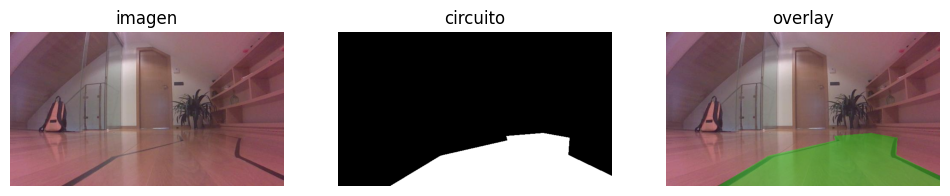

In [5]:
sample_image = sorted(raw_images_dir.glob('*'))[0]
image = cv2.cvtColor(cv2.imread(str(sample_image)), cv2.COLOR_BGR2RGB)
track = cv2.imread(str(raw_track_dir / f'{sample_image.stem}.png'), cv2.IMREAD_GRAYSCALE)
obstacle = cv2.imread(str(raw_obstacle_dir / f'{sample_image.stem}.png'), cv2.IMREAD_GRAYSCALE)

overlay = image.copy()
overlay[track > 0] = (0, 255, 0)
overlay[obstacle > 0] = (255, 0, 0)
blend = cv2.addWeighted(image, 0.65, overlay, 0.35, 0)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1); plt.title('imagen'); plt.imshow(image); plt.axis('off')
plt.subplot(1, 3, 2); plt.title('circuito'); plt.imshow(track, cmap='gray'); plt.axis('off')
plt.subplot(1, 3, 3); plt.title('overlay'); plt.imshow(blend); plt.axis('off')
plt.show()

## 4. Dividir train/val con scikit-learn

In [6]:
def clear_split_dirs():
    for split in ['train', 'val']:
        for sub in ['images', 'track_masks', 'obstacle_masks']:
            reset_dir(DATA_DIR / split / sub)

def copy_triplet(image_path, split):
    shutil.copy2(image_path, DATA_DIR / split / 'images' / image_path.name)
    shutil.copy2(raw_track_dir / f'{image_path.stem}.png', DATA_DIR / split / 'track_masks' / f'{image_path.stem}.png')
    shutil.copy2(raw_obstacle_dir / f'{image_path.stem}.png', DATA_DIR / split / 'obstacle_masks' / f'{image_path.stem}.png')

all_raw_images = sorted(p for p in raw_images_dir.iterdir() if p.suffix.lower() in IMAGE_EXTENSIONS)
train_images, val_images = train_test_split(all_raw_images, test_size=VAL_SIZE, random_state=SEED, shuffle=True)

clear_split_dirs()
for p in train_images:
    copy_triplet(p, 'train')
for p in val_images:
    copy_triplet(p, 'val')

def count_images_with_obstacle(paths):
    count = 0
    for p in paths:
        m = cv2.imread(str(raw_obstacle_dir / f'{p.stem}.png'), cv2.IMREAD_GRAYSCALE)
        count += int(m is not None and np.any(m > 0))
    return count

print('Train:', len(train_images), 'imagenes | con caja:', count_images_with_obstacle(train_images))
print('Val:', len(val_images), 'imagenes | con caja:', count_images_with_obstacle(val_images))
if count_images_with_obstacle(val_images) == 0:
    print('Aviso: validacion no tiene imagenes con caja. Cambia SEED y repite esta celda.')

Train: 45 imagenes | con caja: 26
Val: 12 imagenes | con caja: 5


## 5. Dataset y modelo

In [7]:
class CircuitDataset(Dataset):
    def __init__(self, split_dir, img_size=256):
        self.split_dir = Path(split_dir)
        self.img_size = img_size
        self.images = sorted(p for p in (self.split_dir / 'images').iterdir() if p.suffix.lower() in IMAGE_EXTENSIONS)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image_path = self.images[idx]
        image = Image.open(image_path).convert('RGB').resize((self.img_size, self.img_size), Image.BILINEAR)
        track = Image.open(self.split_dir / 'track_masks' / f'{image_path.stem}.png').convert('L').resize((self.img_size, self.img_size), Image.NEAREST)
        obstacle = Image.open(self.split_dir / 'obstacle_masks' / f'{image_path.stem}.png').convert('L').resize((self.img_size, self.img_size), Image.NEAREST)

        image = torch.from_numpy(np.asarray(image, dtype=np.float32) / 255.0).permute(2, 0, 1)
        track = (np.asarray(track, dtype=np.float32) > 127).astype(np.float32)
        obstacle = (np.asarray(obstacle, dtype=np.float32) > 127).astype(np.float32)
        mask = torch.from_numpy(np.stack([track, obstacle], axis=0))
        return image, mask

class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.block(x)

class SmallUNet(nn.Module):
    def __init__(self, base_channels=32):
        super().__init__()
        c = base_channels
        self.pool = nn.MaxPool2d(2)
        self.enc1 = ConvBlock(3, c)
        self.enc2 = ConvBlock(c, c * 2)
        self.enc3 = ConvBlock(c * 2, c * 4)
        self.enc4 = ConvBlock(c * 4, c * 8)
        self.bottleneck = ConvBlock(c * 8, c * 16)
        self.up4 = nn.ConvTranspose2d(c * 16, c * 8, 2, 2)
        self.dec4 = ConvBlock(c * 16, c * 8)
        self.up3 = nn.ConvTranspose2d(c * 8, c * 4, 2, 2)
        self.dec3 = ConvBlock(c * 8, c * 4)
        self.up2 = nn.ConvTranspose2d(c * 4, c * 2, 2, 2)
        self.dec2 = ConvBlock(c * 4, c * 2)
        self.up1 = nn.ConvTranspose2d(c * 2, c, 2, 2)
        self.dec1 = ConvBlock(c * 2, c)
        self.head = nn.Conv2d(c, 2, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))
        d4 = self.dec4(torch.cat([e4, self.up4(b)], dim=1))
        d3 = self.dec3(torch.cat([e3, self.up3(d4)], dim=1))
        d2 = self.dec2(torch.cat([e2, self.up2(d3)], dim=1))
        d1 = self.dec1(torch.cat([e1, self.up1(d2)], dim=1))
        return self.head(d1)

## 6. Entrenar

In [8]:
class DiceBCELoss(nn.Module):
    def __init__(self, obstacle_weight=1.0):
        super().__init__()
        self.obstacle_weight = obstacle_weight

    def forward(self, logits, targets, smooth=1.0):
        bce_map = F.binary_cross_entropy_with_logits(logits, targets, reduction='none')
        weights = torch.ones_like(targets)
        weights[:, 1:2] = 1.0 + (self.obstacle_weight - 1.0) * targets[:, 1:2]
        bce = (bce_map * weights).mean()

        probs = torch.sigmoid(logits)
        probs_flat = probs.reshape(-1)
        targets_flat = targets.reshape(-1)
        intersection = (probs_flat * targets_flat).sum()
        dice = 1.0 - (2.0 * intersection + smooth) / (probs_flat.sum() + targets_flat.sum() + smooth)
        return bce + dice

def dice_score(logits, targets, threshold=0.5, smooth=1e-8):
    preds = (torch.sigmoid(logits) > threshold).float().reshape(-1)
    targets = targets.reshape(-1)
    intersection = (preds * targets).sum()
    return ((2 * intersection + smooth) / (preds.sum() + targets.sum() + smooth)).item()

train_ds = CircuitDataset(DATA_DIR / 'train', IMG_SIZE)
val_ds = CircuitDataset(DATA_DIR / 'val', IMG_SIZE)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

model = SmallUNet(BASE_CHANNELS).to(DEVICE)
loss_fn = DiceBCELoss(obstacle_weight=OBSTACLE_WEIGHT)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
best_dice = -1.0
epochs_without_improvement = 0
history_rows = []

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss = 0.0
    for images_batch, masks_batch in tqdm(train_loader, desc=f'Epoch {epoch}/{EPOCHS} train', leave=False):
        images_batch = images_batch.to(DEVICE)
        masks_batch = masks_batch.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images_batch)
        loss = loss_fn(logits, masks_batch)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    model.eval()
    val_loss = 0.0
    val_dice = 0.0
    with torch.no_grad():
        for images_batch, masks_batch in val_loader:
            images_batch = images_batch.to(DEVICE)
            masks_batch = masks_batch.to(DEVICE)
            logits = model(images_batch)
            val_loss += loss_fn(logits, masks_batch).item()
            val_dice += dice_score(logits, masks_batch)

    train_loss /= max(1, len(train_loader))
    val_loss /= max(1, len(val_loader))
    val_dice /= max(1, len(val_loader))
    is_best = val_dice > best_dice
    history_rows.append({
        'epoch': epoch,
        'train_loss': train_loss,
        'val_loss': val_loss,
        'val_dice': val_dice,
        'is_best': is_best,
    })
    print(f'Epoch {epoch:03d}: train_loss={train_loss:.4f} val_loss={val_loss:.4f} val_dice={val_dice:.4f}')

    checkpoint = {
        'state_dict': model.state_dict(),
        'optimizer': optimizer.state_dict(),
        'epoch': epoch,
        'img_size': IMG_SIZE,
        'base_channels': BASE_CHANNELS,
        'out_channels': 2,
        'best_metric': best_dice,
        'history': history_rows,
    }
    torch.save(checkpoint, CHECKPOINT_DIR / 'last_model.pth')
    if is_best:
        best_dice = val_dice
        checkpoint['best_metric'] = best_dice
        torch.save(checkpoint, CHECKPOINT_DIR / 'best_model.pth')
        print('  nuevo mejor modelo guardado')
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            print(f'  early stopping en epoch {epoch:03d} (sin mejora en {EARLY_STOPPING_PATIENCE} epochs)')
            break

history_df = pd.DataFrame(history_rows)
if not history_df.empty:
    history_df[['train_loss', 'val_loss', 'val_dice']] = history_df[['train_loss', 'val_loss', 'val_dice']].round(4)
display(history_df)
print(f'Mejor val_dice: {best_dice:.4f}')


Epoch 1/150 train:   0%|          | 0/6 [00:00<?, ?it/s]

Epoch 001: train_loss=1.4158 val_loss=1.5459 val_dice=0.0000
  nuevo mejor modelo guardado


Epoch 2/150 train:   0%|          | 0/6 [00:00<?, ?it/s]

Epoch 002: train_loss=1.2463 val_loss=1.5017 val_dice=0.0090
  nuevo mejor modelo guardado


Epoch 3/150 train:   0%|          | 0/6 [00:00<?, ?it/s]

...

Epoch 097: train_loss=0.0445 val_loss=0.1543 val_dice=0.9359


Epoch 98/150 train:   0%|          | 0/6 [00:00<?, ?it/s]

Epoch 098: train_loss=0.0483 val_loss=0.1436 val_dice=0.9423
  early stopping en epoch 098 (sin mejora en 20 epochs)


,epoch,train_loss,val_loss,val_dice,is_best
0,1,1.4158,1.5459,0.0000,True
1,2,1.2463,1.5017,0.0090,True
2,3,1.1783,1.3845,0.5932,True
3,4,1.0994,4.3154,0.2580,False
4,5,1.0297,1.2962,0.5790,False
...,...,...,...,...,...
93,94,0.0527,0.1508,0.9381,False
94,95,0.0470,0.1591,0.9346,False
95,96,0.0479,0.1498,0.9383,False
96,97,0.0445,0.1543,0.9359,False


Mejor val_dice: 0.9519


## 7. Probar una prediccion

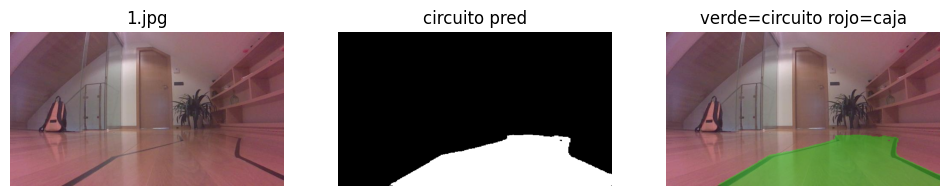

True

In [9]:
checkpoint = torch.load(CHECKPOINT_DIR / 'best_model.pth', map_location=DEVICE)
model.load_state_dict(checkpoint['state_dict'])
model.eval()

test_image_path = sorted((DATA_DIR / 'val' / 'images').glob('*'))[0]
orig_bgr = cv2.imread(str(test_image_path))
orig_rgb = cv2.cvtColor(orig_bgr, cv2.COLOR_BGR2RGB)
resized = cv2.resize(orig_rgb, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
tensor = torch.from_numpy(resized.astype(np.float32) / 255.0).permute(2, 0, 1).unsqueeze(0).to(DEVICE)

with torch.no_grad():
    probs = torch.sigmoid(model(tensor))[0].cpu().numpy()

track_pred = (probs[0] > 0.5).astype(np.uint8) * 255
obstacle_pred = (probs[1] > 0.5).astype(np.uint8) * 255
track_pred = cv2.resize(track_pred, (orig_rgb.shape[1], orig_rgb.shape[0]), interpolation=cv2.INTER_NEAREST)
obstacle_pred = cv2.resize(obstacle_pred, (orig_rgb.shape[1], orig_rgb.shape[0]), interpolation=cv2.INTER_NEAREST)

overlay = orig_rgb.copy()
overlay[track_pred > 0] = (0, 255, 0)
overlay[obstacle_pred > 0] = (255, 0, 0)
blend = cv2.addWeighted(orig_rgb, 0.65, overlay, 0.35, 0)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1); plt.title(test_image_path.name); plt.imshow(orig_rgb); plt.axis('off')
plt.subplot(1, 3, 2); plt.title('circuito pred'); plt.imshow(track_pred, cmap='gray'); plt.axis('off')
plt.subplot(1, 3, 3); plt.title('verde=circuito rojo=caja'); plt.imshow(blend); plt.axis('off')
plt.show()

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
cv2.imwrite(str(OUTPUT_DIR / 'notebook_prediccion.png'), cv2.cvtColor(blend, cv2.COLOR_RGB2BGR))

## 7B. Revisar varias predicciones

Este bloque prueba varias imagenes y guarda resultados en `outputs/revision_lote/`.

Verde = circuito. Rojo = caja.


Imagenes a revisar: 12
Guardando en: /home/juan/Documentos/vision_avanzada/main/TFM/circuito_segmentation/outputs/revision_lote


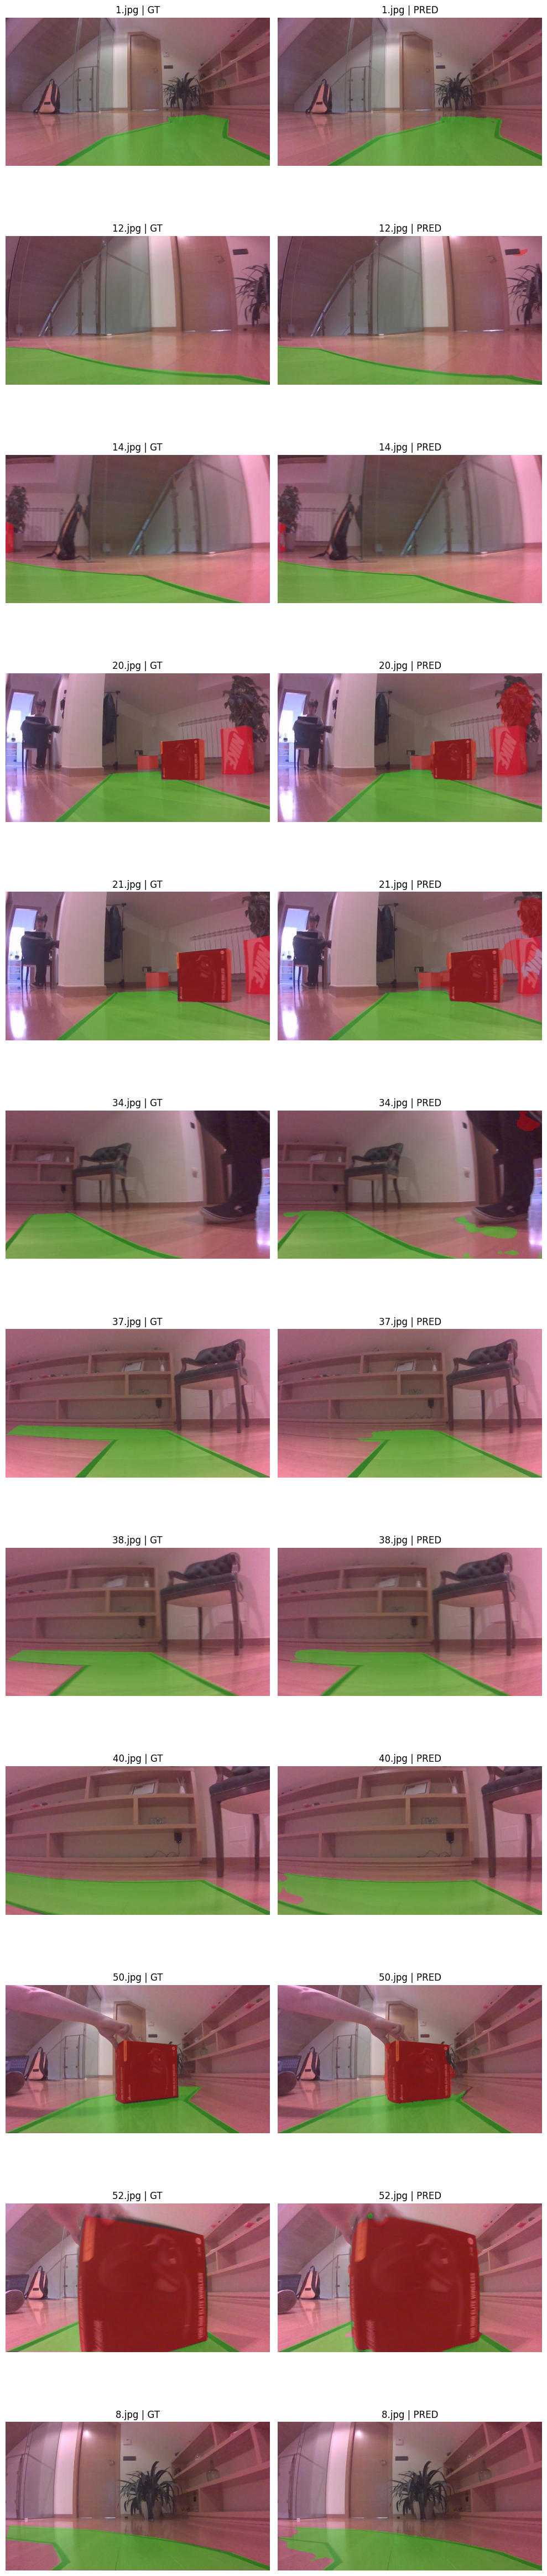

Revision guardada en: /home/juan/Documentos/vision_avanzada/main/TFM/circuito_segmentation/outputs/revision_lote


In [10]:
REVISION_SOURCE = DATA_DIR / 'val' / 'images'  # Cambia a otra carpeta si quieres
REVISION_MAX_IMAGES = 12                     # Pon None para revisar todas
REVISION_THRESHOLD = 0.5
REVISION_OUT_DIR = OUTPUT_DIR / 'revision_lote'
REVISION_OUT_DIR.mkdir(parents=True, exist_ok=True)

checkpoint = torch.load(CHECKPOINT_DIR / 'best_model.pth', map_location=DEVICE)
model.load_state_dict(checkpoint['state_dict'])
model.eval()

review_images = sorted(
    p for p in Path(REVISION_SOURCE).iterdir()
    if p.suffix.lower() in IMAGE_EXTENSIONS
)
if REVISION_MAX_IMAGES is not None:
    review_images = review_images[:REVISION_MAX_IMAGES]

print('Imagenes a revisar:', len(review_images))
print('Guardando en:', REVISION_OUT_DIR)

def make_overlay(rgb_image, track_mask, obstacle_mask, alpha=0.35):
    overlay = rgb_image.copy()
    overlay[track_mask > 0] = (0, 255, 0)
    overlay[obstacle_mask > 0] = (255, 0, 0)
    return cv2.addWeighted(rgb_image, 1.0 - alpha, overlay, alpha, 0)

def load_ground_truth_masks(image_path):
    split_dir = image_path.parent.parent
    track_path = split_dir / 'track_masks' / f'{image_path.stem}.png'
    obstacle_path = split_dir / 'obstacle_masks' / f'{image_path.stem}.png'
    if not track_path.exists() or not obstacle_path.exists():
        return None, None
    track = cv2.imread(str(track_path), cv2.IMREAD_GRAYSCALE)
    obstacle = cv2.imread(str(obstacle_path), cv2.IMREAD_GRAYSCALE)
    return track, obstacle

cols = 2
rows = max(1, len(review_images))
plt.figure(figsize=(10, 4 * rows))

for row_idx, image_path in enumerate(review_images):
    orig_bgr = cv2.imread(str(image_path))
    if orig_bgr is None:
        print('No pude leer:', image_path)
        continue

    orig_rgb = cv2.cvtColor(orig_bgr, cv2.COLOR_BGR2RGB)
    gt_track, gt_obstacle = load_ground_truth_masks(image_path)
    if gt_track is not None:
        gt_track = cv2.resize(gt_track, (orig_rgb.shape[1], orig_rgb.shape[0]), interpolation=cv2.INTER_NEAREST)
        gt_obstacle = cv2.resize(gt_obstacle, (orig_rgb.shape[1], orig_rgb.shape[0]), interpolation=cv2.INTER_NEAREST)
        gt_blend = make_overlay(orig_rgb, gt_track, gt_obstacle)
        cv2.imwrite(str(REVISION_OUT_DIR / f'{image_path.stem}_ground_truth.png'), cv2.cvtColor(gt_blend, cv2.COLOR_RGB2BGR))
    else:
        gt_blend = orig_rgb.copy()
        print('Sin ground truth para:', image_path.name)

    resized = cv2.resize(orig_rgb, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    tensor = torch.from_numpy(resized.astype(np.float32) / 255.0).permute(2, 0, 1).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        probs = torch.sigmoid(model(tensor))[0].cpu().numpy()

    track_pred = (probs[0] > REVISION_THRESHOLD).astype(np.uint8) * 255
    obstacle_pred = (probs[1] > REVISION_THRESHOLD).astype(np.uint8) * 255
    track_pred = cv2.resize(track_pred, (orig_rgb.shape[1], orig_rgb.shape[0]), interpolation=cv2.INTER_NEAREST)
    obstacle_pred = cv2.resize(obstacle_pred, (orig_rgb.shape[1], orig_rgb.shape[0]), interpolation=cv2.INTER_NEAREST)
    pred_blend = make_overlay(orig_rgb, track_pred, obstacle_pred)

    cv2.imwrite(str(REVISION_OUT_DIR / f'{image_path.stem}_prediction.png'), cv2.cvtColor(pred_blend, cv2.COLOR_RGB2BGR))
    cv2.imwrite(str(REVISION_OUT_DIR / f'{image_path.stem}_track_mask.png'), track_pred)
    cv2.imwrite(str(REVISION_OUT_DIR / f'{image_path.stem}_obstacle_mask.png'), obstacle_pred)

    plt.subplot(rows, cols, row_idx * cols + 1)
    plt.title(f'{image_path.name} | GT')
    plt.imshow(gt_blend)
    plt.axis('off')

    plt.subplot(rows, cols, row_idx * cols + 2)
    plt.title(f'{image_path.name} | PRED')
    plt.imshow(pred_blend)
    plt.axis('off')

plt.tight_layout()
plt.show()
print('Revision guardada en:', REVISION_OUT_DIR)


## 8. Exportar a ONNX

In [11]:
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)
torch.onnx.export(
    model,
    dummy,
    str(EXPORT_DIR / 'circuit_unet.onnx'),
    input_names=['image'],
    output_names=['logits'],
    opset_version=12,
)
print('Exportado:', EXPORT_DIR / 'circuit_unet.onnx')

W0509 17:04:40.633000 24782 torch/onnx/_internal/exporter/_compat.py:125] Setting ONNX exporter to use operator set version 18 because the requested opset_version 12 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


[torch.onnx] Obtain model graph for `SmallUNet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `SmallUNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decomposition...


/usr/lib/python3.12/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)
The model version conversion is not supported by the onnxscript version converter and fallback is enabled. The model will be converted using the onnx C API (target version: 12).


[torch.onnx] Run decomposition... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅


Failed to convert the model to the target version 12 using the ONNX C API. The model was not modified
Traceback (most recent call last):
  File "/home/juan/venvs/vision/lib/python3.12/site-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
                      ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/juan/venvs/vision/lib/python3.12/site-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
             ^^^^^^^^^^^
  File "/home/juan/venvs/vision/lib/python3.12/site-packages/onnxscript/version_converter/__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/juan/venvs/vision/lib/python3.12/site-packages/onnx/version_converter.py", line 39, in convert_version
    converted_model_str = C.convert_version(model_str, target_version)
                         

Exportado: /home/juan/Documentos/vision_avanzada/main/TFM/circuito_segmentation/exports/circuit_unet.onnx
